In [1]:
# ============================================================
# Importación de librerías
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: preprocesamiento, modelos y métricas
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    f1_score,
    silhouette_score
)

import networkx as nx

# Configuraciones estéticas para las gráficas
sns.set(style="whitegrid", palette="muted", font_scale=1.2)

# Opcional: para ver más columnas en DataFrames
pd.set_option("display.max_columns", None)


In [3]:
# ============================================================
# SECCIÓN 1 — Carga y preprocesamiento del dataset
# ============================================================

# 1. Cargar el archivo CSV en un DataFrame
ruta_csv = "data.csv"   # nombre del archivo (asegúrate que está en la misma carpeta del notebook)
df = pd.read_csv(ruta_csv)

print("Dimensiones originales del dataset:", df.shape)
display(df.head())

# 2. Eliminar columna basura si existe
#   En este dataset suele aparecer una columna llamada "Unnamed: 32" que no contiene información útil.
df = df.drop(columns=["Unnamed: 32"], errors="ignore")

# 3. Convertir la variable objetivo 'diagnosis' a binaria: M=1 (maligno), B=0 (benigno)
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

# 4. Eliminar la columna 'id' porque no aporta información al modelo
df = df.drop(columns=["id"])

# 5. Revisar si hay valores nulos en alguna columna
print("\nValores nulos por columna:")
print(df.isnull().sum())

# 6. Separar X (features) e y (target)
#    X: todas las columnas explicativas
#    y: solo la columna de diagnóstico (0/1)
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

print("\nShape X (solo variables explicativas):", X.shape)
print("Shape y (variable objetivo):", y.shape)

# 7. Escalar las variables numéricas (importante para k-NN y PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 8. Convertir X_scaled a DataFrame con nombres de columnas
X_tabular_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print("\nDimensiones de X_tabular_scaled:", X_tabular_scaled.shape)
display(X_tabular_scaled.head())


Dimensiones originales del dataset: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN



Valores nulos por columna:
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

Shape X (solo variables explicativas): (569, 30)
Shape y (v

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,2.489734,-0.565265,2.833031,2.487578,-0.214002,1.316862,0.724026,0.660820,1.148757,0.907083,1.886690,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,0.499255,-0.876244,0.263327,0.742402,-0.605351,-0.692926,-0.440780,0.260162,-0.805450,-0.099444,1.805927,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,1.228676,-0.780083,0.850928,1.181336,-0.297005,0.814974,0.213076,1.424827,0.237036,0.293559,1.511870,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,0.326373,-0.110409,0.286593,-0.288378,0.689702,2.744280,0.819518,1.115007,4.732680,2.047511,-0.281464,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,1.270543,-0.790244,1.273189,1.190357,1.483067,-0.048520,0.828471,1.144205,-0.361092,0.499328,1.298575,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100


In [4]:
# ============================================================
# SECCIÓN 2 — Construcción del grafo k-NN y extracción de features de grafo
# ============================================================

# 1. Definición del modelo k-NN sobre los datos escalados
k_vecinos = 10  # número de vecinos más cercanos que usaremos en el grafo

nn_model = NearestNeighbors(n_neighbors=k_vecinos, metric="euclidean")
nn_model.fit(X_tabular_scaled)

# Distancias e índices de los k vecinos más cercanos para cada punto
distancias, indices_vecinos = nn_model.kneighbors(X_tabular_scaled)

print("Shape de distancias:", distancias.shape)
print("Shape de indices_vecinos:", indices_vecinos.shape)

# 2. Construcción del grafo no dirigido
n_muestras = X_tabular_scaled.shape[0]  # número de filas (pacientes)

G = nx.Graph()  # creamos un grafo vacío
G.add_nodes_from(range(n_muestras))  # añadimos nodos 0, 1, 2, ..., n_muestras-1

# Añadir aristas según los k vecinos más cercanos
for i in range(n_muestras):
    for j in indices_vecinos[i]:
        if i != j:  # evitar arista de un nodo consigo mismo
            G.add_edge(i, j)

print("\nNúmero de nodos en el grafo:", G.number_of_nodes())
print("Número de aristas en el grafo:", G.number_of_edges())

# 3. Cálculo de features de grafo para cada nodo

# 3.1 Grado (número de vecinos)
degree_dict = dict(G.degree())

# 3.2 Coeficiente de clustering local
clustering_dict = nx.clustering(G)

# 3.3 Closeness centrality (centralidad de cercanía)
closeness_dict = nx.closeness_centrality(G)

# 3.4 Betweenness centrality (centralidad de intermediación)
betweenness_dict = nx.betweenness_centrality(G, normalized=True)

# 3.5 Eigenvector centrality (centralidad de vector propio)
eigenvector_dict = nx.eigenvector_centrality_numpy(G)

# 3.6 PageRank
pagerank_dict = nx.pagerank(G)

# 3.7 Proporción de vecinos malignos (usando y)
y_array = y.to_numpy()
prop_malign_neighbors = {}

for node in G.nodes():
    vecinos = list(G.neighbors(node))
    if len(vecinos) == 0:
        prop_malign_neighbors[node] = 0.0
    else:
        etiquetas_vecinos = y_array[vecinos]  # toma la etiqueta (0/1) de cada vecino
        prop_malign_neighbors[node] = etiquetas_vecinos.mean()  # promedio = proporción de 1s

# 4. Convertir todas las features de grafo a un DataFrame

graph_features = pd.DataFrame({
    "degree": pd.Series(degree_dict),
    "clustering": pd.Series(clustering_dict),
    "closeness": pd.Series(closeness_dict),
    "betweenness": pd.Series(betweenness_dict),
    "eigenvector": pd.Series(eigenvector_dict),
    "pagerank": pd.Series(pagerank_dict),
    "prop_malign_neighbors": pd.Series(prop_malign_neighbors)
})

# Asegurarnos de que el índice esté ordenado por número de nodo
graph_features = graph_features.sort_index()

print("\nDimensiones de graph_features:", graph_features.shape)
display(graph_features.head())

# 5. Construir la matriz final X_total (tabular + grafo)

X_total = pd.concat(
    [X_tabular_scaled.reset_index(drop=True),
     graph_features.reset_index(drop=True)],
    axis=1
)

print("\nDimensiones de X_tabular_scaled:", X_tabular_scaled.shape)
print("Dimensiones de graph_features:", graph_features.shape)
print("Dimensiones de X_total (tabular + grafo):", X_total.shape)

display(X_total.head())


Shape de distancias: (569, 10)
Shape de indices_vecinos: (569, 10)

Número de nodos en el grafo: 569
Número de aristas en el grafo: 3851

Dimensiones de graph_features: (569, 7)


,degree,clustering,closeness,betweenness,eigenvector,pagerank,prop_malign_neighbors
0,12,0.439394,0.202857,0.000442,0.003996,0.001603,1.0
1,11,0.527273,0.237558,0.001954,0.005794,0.001474,1.0
2,17,0.389706,0.218882,0.001829,0.008084,0.002093,1.0
3,9,0.500000,0.214178,0.000254,0.004168,0.001294,1.0
4,10,0.222222,0.235002,0.002210,0.004991,0.001355,1.0



Dimensiones de X_tabular_scaled: (569, 30)
Dimensiones de graph_features: (569, 7)
Dimensiones de X_total (tabular + grafo): (569, 37)


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,degree,clustering,closeness,betweenness,eigenvector,pagerank,prop_malign_neighbors
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,2.489734,-0.565265,2.833031,2.487578,-0.214002,1.316862,0.724026,0.660820,1.148757,0.907083,1.886690,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015,12,0.439394,0.202857,0.000442,0.003996,0.001603,1.0
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,0.499255,-0.876244,0.263327,0.742402,-0.605351,-0.692926,-0.440780,0.260162,-0.805450,-0.099444,1.805927,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190,11,0.527273,0.237558,0.001954,0.005794,0.001474,1.0
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,1.228676,-0.780083,0.850928,1.181336,-0.297005,0.814974,0.213076,1.424827,0.237036,0.293559,1.511870,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391,17,0.389706,0.218882,0.001829,0.008084,0.002093,1.0
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,0.326373,-0.110409,0.286593,-0.288378,0.689702,2.744280,0.819518,1.115007,4.732680,2.047511,-0.281464,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010,9,0.500000,0.214178,0.000254,0.004168,0.001294,1.0
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,1.270543,-0.790244,1.273189,1.190357,1.483067,-0.048520,0.828471,1.144205,-0.361092,0.499328,1.298575,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100,10,0.222222,0.235002,0.002210,0.004991,0.001355,1.0


Varianza explicada por cada componente: [0.44272026 0.18971182]
Varianza total explicada: 0.6324320765155944


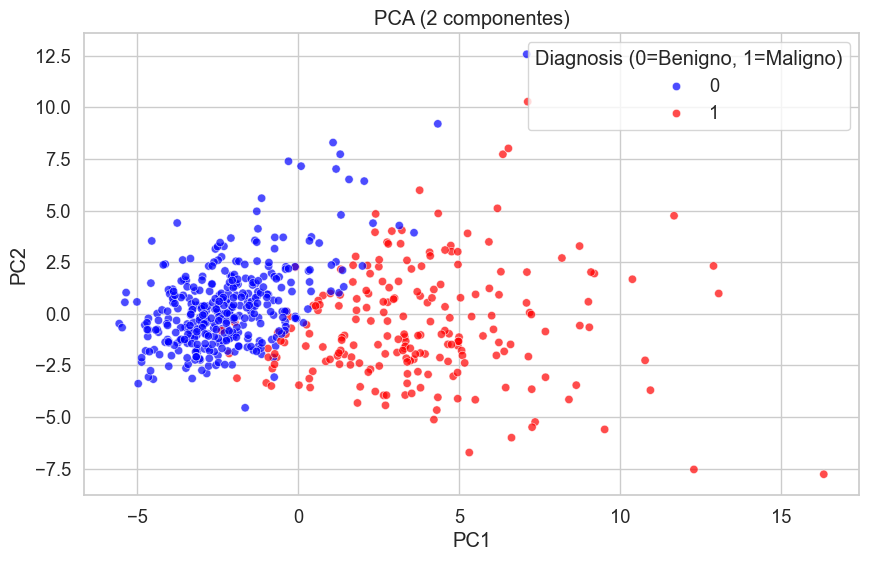

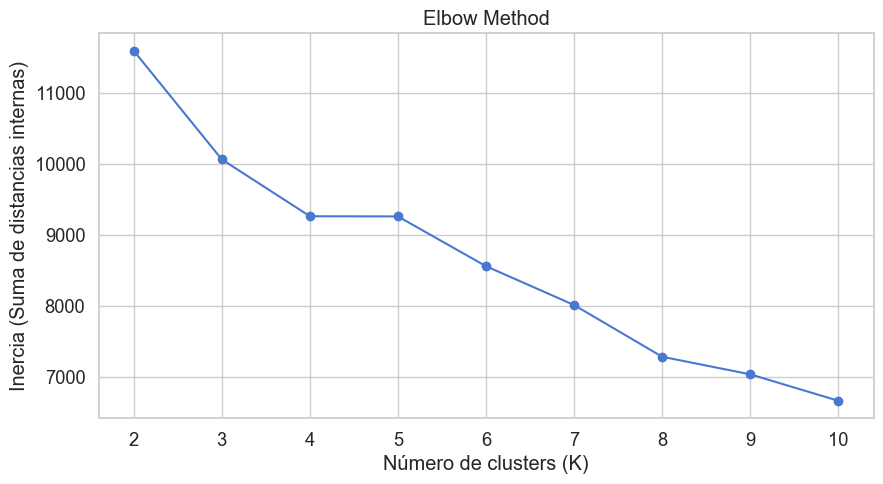

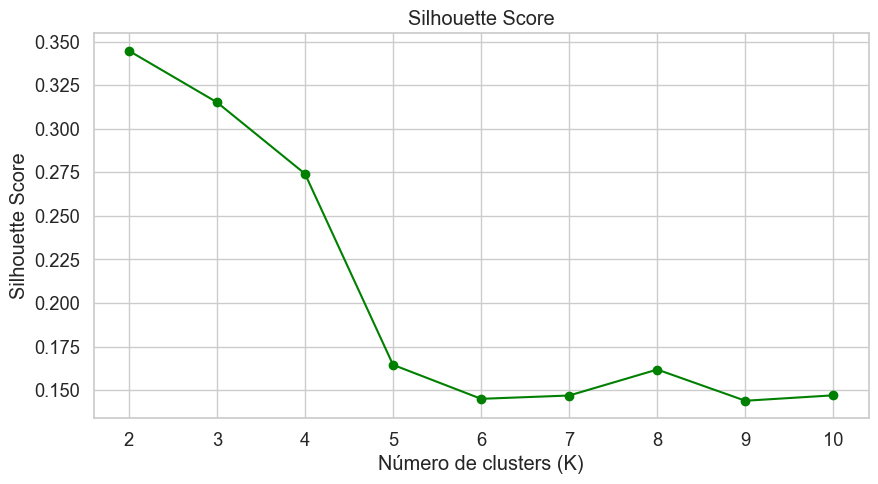

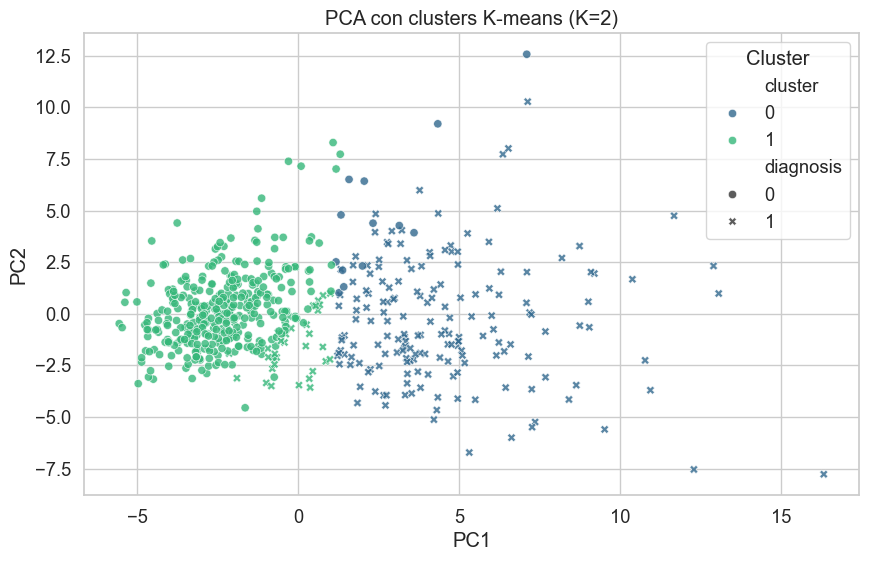

In [10]:
# ============================================================
# SECCIÓN 3 — PCA y K-means
# ============================================================

# ---------------------------
# 1. PCA: Reducir de 30D a 2D
# ---------------------------

pca = PCA(n_components=2)  # Queremos 2 componentes principales
X_pca = pca.fit_transform(X_tabular_scaled)

print("Varianza explicada por cada componente:", pca.explained_variance_ratio_)
print("Varianza total explicada:", pca.explained_variance_ratio_.sum())

# Convertimos a DataFrame para graficar cómodo
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "diagnosis": y.values
})

# ---------------------------
# 2. Gráfica PCA coloreada por diagnóstico
# ---------------------------

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="diagnosis",
    palette={0: "blue", 1: "red"},
    alpha=0.7
)
plt.title("PCA (2 componentes)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Diagnosis (0=Benigno, 1=Maligno)")
plt.show()

# ---------------------------
# 3. K-means con varios K
# ---------------------------

inertias = []
silhouettes = []
K_values = range(2, 11)  # probamos de K=2 a K=10

for k in K_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_tabular_scaled)
    
    inertias.append(kmeans.inertia_)  # suma de distancias internas del cluster
    
    silhouette_avg = silhouette_score(X_tabular_scaled, labels)
    silhouettes.append(silhouette_avg)

# Gráfica del Elbow Method
plt.figure(figsize=(10, 5))
plt.plot(K_values, inertias, marker='o')
plt.title("Elbow Method")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia (Suma de distancias internas)")
plt.grid(True)
plt.show()

# Gráfica de Silhouette Score
plt.figure(figsize=(10, 5))
plt.plot(K_values, silhouettes, marker='o', color='green')
plt.title("Silhouette Score")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

# ---------------------------
# 4. Visualizar clusters finales (tomemos K=2 para este dataset)
# ---------------------------

k_optimo = 2
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42)
clusters = kmeans_final.fit_predict(X_tabular_scaled)

pca_df["cluster"] = clusters

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="viridis",
    style="diagnosis",
    alpha=0.8
)
plt.title(f"PCA con clusters K-means (K={k_optimo})")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.show()


In [6]:
# ============================================================
# SECCIÓN 4 — Random Forest (Tabular vs Tabular + Grafo)
# ============================================================

# 1. Separar datos en train y test
X_train_tab, X_test_tab, y_train, y_test = train_test_split(
    X_tabular_scaled, y, test_size=0.2, random_state=42, stratify=y
)

X_train_tot, X_test_tot, _, _ = train_test_split(
    X_total, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Modelo Random Forest SOLO con datos tabulares
rf_tab = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    random_state=42,
    class_weight="balanced"
)

rf_tab.fit(X_train_tab, y_train)

y_pred_tab = rf_tab.predict(X_test_tab)
y_prob_tab = rf_tab.predict_proba(X_test_tab)[:, 1]

# 3. Modelo Random Forest con datos tabulares + grafo
rf_tot = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    random_state=42,
    class_weight="balanced"
)

rf_tot.fit(X_train_tot, y_train)

y_pred_tot = rf_tot.predict(X_test_tot)
y_prob_tot = rf_tot.predict_proba(X_test_tot)[:, 1]

# 4. Métricas para comparar
acc_tab = accuracy_score(y_test, y_pred_tab)
f1_tab = f1_score(y_test, y_pred_tab)
auc_tab = roc_auc_score(y_test, y_prob_tab)

acc_tot = accuracy_score(y_test, y_pred_tot)
f1_tot = f1_score(y_test, y_pred_tot)
auc_tot = roc_auc_score(y_test, y_prob_tot)

print("\n========== RESULTADOS RANDOM FOREST ==========\n")

print("Modelo SOLO TABULAR")
print(f"Accuracy:  {acc_tab:.4f}")
print(f"F1 Score:  {f1_tab:.4f}")
print(f"AUC ROC:   {auc_tab:.4f}")

print("\n----------------------------------------------\n")

print("Modelo TABULAR + GRAFO")
print(f"Accuracy:  {acc_tot:.4f}")
print(f"F1 Score:  {f1_tot:.4f}")
print(f"AUC ROC:   {auc_tot:.4f}")

print("\n----------------------------------------------")
print("DIFERENCIAS (GRAFO - TABULAR)")
print(f"Accuracy:  {acc_tot - acc_tab:.4f}")
print(f"F1 Score:  {f1_tot - f1_tab:.4f}")
print(f"AUC ROC:   {auc_tot - auc_tab:.4f}")



========== RESULTADOS RANDOM FOREST ==========

Modelo SOLO TABULAR
Accuracy:  0.9649
F1 Score:  0.9500
AUC ROC:   0.9970

----------------------------------------------

Modelo TABULAR + GRAFO
Accuracy:  0.9561
F1 Score:  0.9367
AUC ROC:   0.9974

----------------------------------------------
DIFERENCIAS (GRAFO - TABULAR)
Accuracy:  -0.0088
F1 Score:  -0.0133
AUC ROC:   0.0003



Top 15 variables más importantes:



,feature,importance
36,prop_malign_neighbors,0.172572
22,perimeter_worst,0.127780
27,concave points_worst,0.105176
20,radius_worst,0.081458
7,concave points_mean,0.074913
23,area_worst,0.063087
34,eigenvector,0.047615
0,radius_mean,0.044163
2,perimeter_mean,0.040618
6,concavity_mean,0.037143


C:\Users\jonat\AppData\Local\Temp\ipykernel_49120\1327242948.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


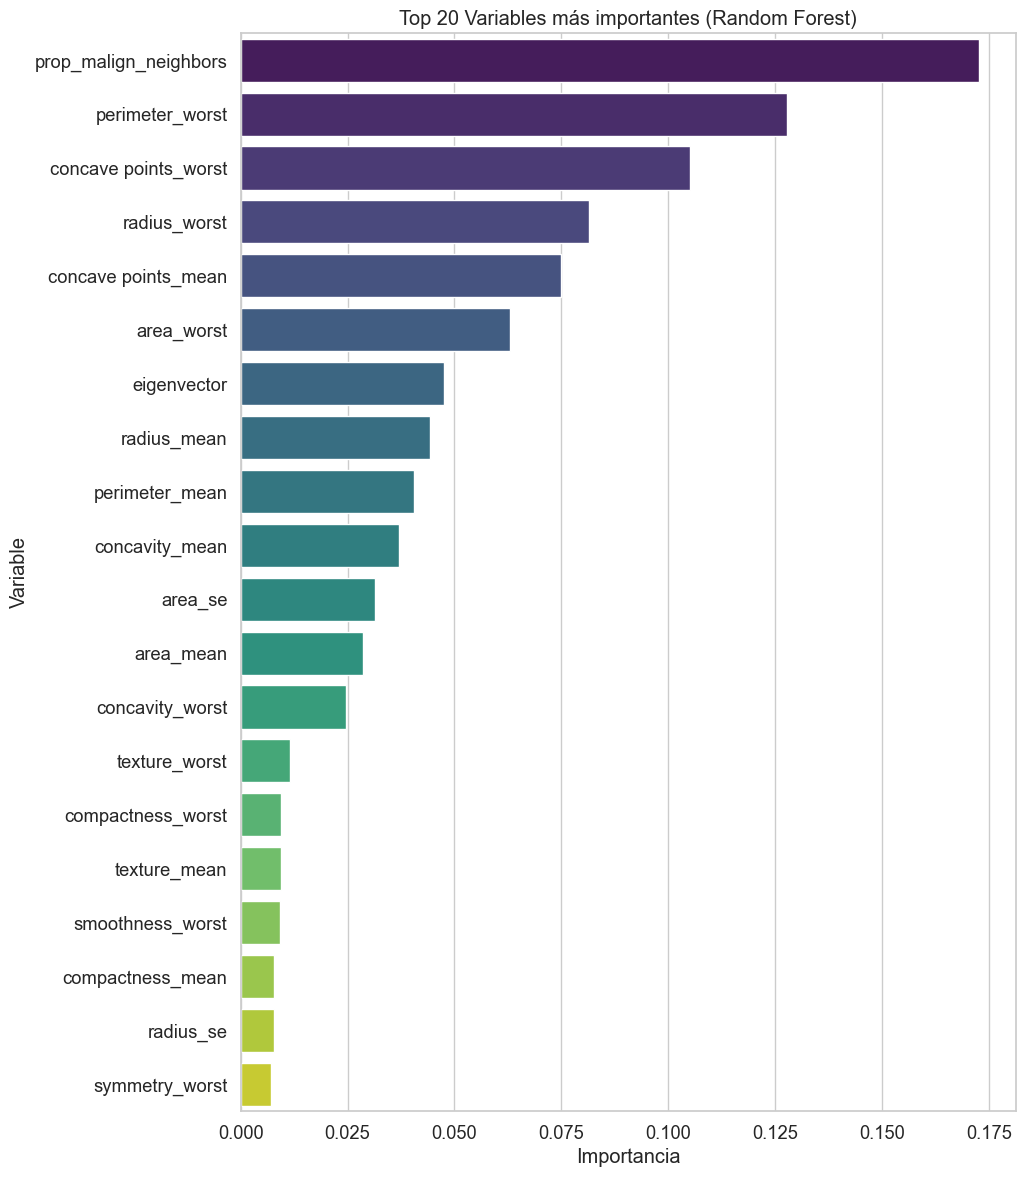

In [7]:
# ============================================================
# SECCIÓN 5 — Importancia de Variables (Feature Importance)
# ============================================================

# Entrenamos un Random Forest con TODOS los features juntos
rf_importance = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)
rf_importance.fit(X_total, y)

# Obtenemos la importancia de cada variable
importances = rf_importance.feature_importances_

# Creamos un dataframe ordenado
feature_names = X_total.columns
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(by="importance", ascending=False)

print("\nTop 15 variables más importantes:\n")
display(importance_df.head(15))

# Gráfica completa
plt.figure(figsize=(10, 14))
sns.barplot(
    data=importance_df.head(20),
    x="importance",
    y="feature",
    palette="viridis"
)
plt.title("Top 20 Variables más importantes (Random Forest)")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.show()


AUC con grafo REAL (test): 0.9973544973544974
Permutación 1/20 — AUC (test): 0.9974
Permutación 2/20 — AUC (test): 0.9964
Permutación 3/20 — AUC (test): 0.9970
Permutación 4/20 — AUC (test): 0.9970
Permutación 5/20 — AUC (test): 0.9957
Permutación 6/20 — AUC (test): 0.9965
Permutación 7/20 — AUC (test): 0.9980
Permutación 8/20 — AUC (test): 0.9964
Permutación 9/20 — AUC (test): 0.9964
Permutación 10/20 — AUC (test): 0.9970
Permutación 11/20 — AUC (test): 0.9954
Permutación 12/20 — AUC (test): 0.9964
Permutación 13/20 — AUC (test): 0.9960
Permutación 14/20 — AUC (test): 0.9974
Permutación 15/20 — AUC (test): 0.9970
Permutación 16/20 — AUC (test): 0.9957
Permutación 17/20 — AUC (test): 0.9974
Permutación 18/20 — AUC (test): 0.9964
Permutación 19/20 — AUC (test): 0.9974
Permutación 20/20 — AUC (test): 0.9960


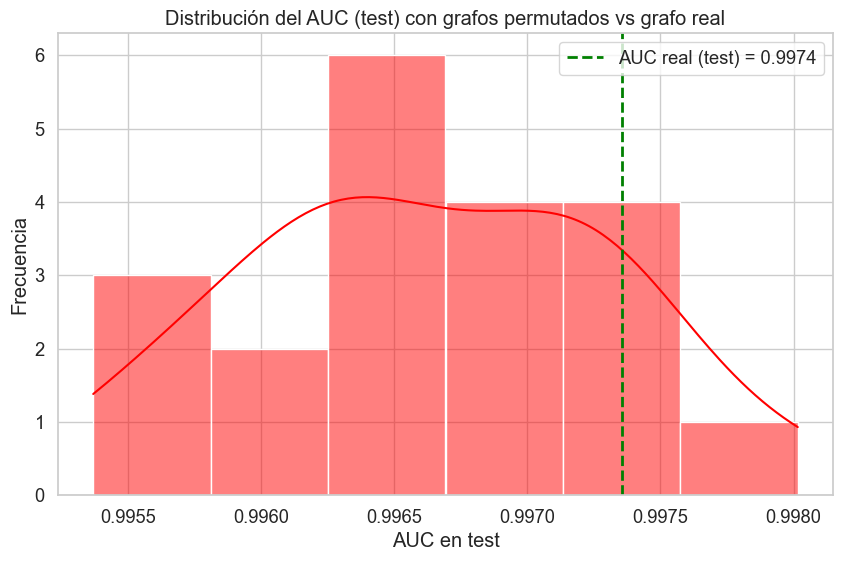


AUC real (test): 0.9973544973544974
AUC promedio permutado (test): 0.9966352513227512
AUC permutado mínimo (test): 0.9953703703703703
AUC permutado máximo (test): 0.998015873015873


In [9]:
# ============================================================
# SECCIÓN 6 — Permutación de aristas del grafo (con train/test)
# ============================================================

def compute_graph_features(G, y_series):
    """
    Extrae las mismas 7 características de grafo usadas antes.
    Recibe un grafo y la serie y (diagnosis) y regresa un DataFrame
    con las features de grafo, indexadas por nodo.
    """
    deg = dict(G.degree())
    clustering = nx.clustering(G)
    closeness = nx.closeness_centrality(G)
    betweenness = nx.betweenness_centrality(G)
    eigen = nx.eigenvector_centrality(G, max_iter=500)
    pagerank = nx.pagerank(G)

    y_array = y_series.to_numpy()
    malign_prop = []
    for node in G.nodes():
        vecinos = list(G.neighbors(node))
        if len(vecinos) == 0:
            malign_prop.append(0.0)
        else:
            malign_prop.append(y_array[vecinos].mean())

    graph_df = pd.DataFrame({
        "degree": pd.Series(deg),
        "clustering": pd.Series(clustering),
        "closeness": pd.Series(closeness),
        "betweenness": pd.Series(betweenness),
        "eigenvector": pd.Series(eigen),
        "pagerank": pd.Series(pagerank),
        "prop_malign_neighbors": malign_prop
    })

    # Aseguramos que esté ordenado por índice de nodo
    graph_df = graph_df.sort_index()
    return graph_df


# -------- 1. Features con el GRAFO REAL --------

real_graph_features = compute_graph_features(G, y)

# X_total_real: tabular + grafo real (manteniendo índices originales)
X_total_real = pd.concat([X_tabular_scaled, real_graph_features], axis=1)

# -------- 2. Hacemos UNA sola partición train/test --------

X_train_real, X_test_real, y_train, y_test = train_test_split(
    X_total_real, y, test_size=0.2, random_state=42, stratify=y
)

# Guardamos los índices para reutilizarlos en las permutaciones
train_idx = X_train_real.index
test_idx = X_test_real.index

# -------- 3. AUC con el grafo REAL --------

rf_real = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

rf_real.fit(X_train_real, y_train)
y_prob_real = rf_real.predict_proba(X_test_real)[:, 1]
auc_real = roc_auc_score(y_test, y_prob_real)

print("AUC con grafo REAL (test):", auc_real)


# -------- 4. Permutación de aristas y AUC en test --------

n_permutaciones = 20
auc_permutados = []

for i in range(n_permutaciones):
    # Copiamos el grafo original y hacemos swaps de aristas
    G_perm = G.copy()
    nx.double_edge_swap(G_perm, nswap=2000, max_tries=5000)

    # Recalculamos features de grafo
    perm_features = compute_graph_features(G_perm, y)

    # Construimos X_total_perm manteniendo el mismo orden de índices
    X_total_perm = pd.concat([X_tabular_scaled, perm_features], axis=1)

    # Usamos EXACTAMENTE los mismos índices de train y test que antes
    X_train_perm = X_total_perm.loc[train_idx]
    X_test_perm = X_total_perm.loc[test_idx]

    rf_perm = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    )

    rf_perm.fit(X_train_perm, y_train)
    y_prob_perm = rf_perm.predict_proba(X_test_perm)[:, 1]
    auc_perm = roc_auc_score(y_test, y_prob_perm)
    auc_permutados.append(auc_perm)

    print(f"Permutación {i+1}/{n_permutaciones} — AUC (test): {auc_perm:.4f}")


# -------- 5. Comparar distribuciones --------

plt.figure(figsize=(10, 6))
sns.histplot(auc_permutados, kde=True, color="red")
plt.axvline(auc_real, color="green", linestyle="--", linewidth=2,
            label=f"AUC real (test) = {auc_real:.4f}")
plt.title("Distribución del AUC (test) con grafos permutados vs grafo real")
plt.xlabel("AUC en test")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

print("\nAUC real (test):", auc_real)
print("AUC promedio permutado (test):", np.mean(auc_permutados))
print("AUC permutado mínimo (test):", np.min(auc_permutados))
print("AUC permutado máximo (test):", np.max(auc_permutados))
